# 附录C：进阶方法的入口

In [1]:
from pathlib import Path
import sys
root = Path.cwd().resolve()
while not (root / 'lsq').is_dir():
    if root == root.parent:
        raise RuntimeError('Run inside the repository')
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from lsq import (finite_difference, whiten, gauss_newton,
                 levenberg_marquardt, dogleg, recursive_update)
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (6.4, 3.3), 'font.size': 10,
                     'axes.grid': True, 'savefig.dpi': 130})

这篇是进阶选读。第一次学会直线拟合、加权、检查残差和使用成熟求解器后，已经能做许多事，不必为了“读完”硬啃这里。

这里再问两个实际问题：有些参数能直接算，为什么跟着一起慢慢试？每次重算影响表很贵，能不能利用上一次走路留下的信息？

## 能直接算的先算：可分最小二乘

对 $a e^{-kt}+c$，难的是 $k$。一旦先选定 $k$，$a,c$ 就只是两种已知零件的系数，可以线性求解。因此可以外层只试下降速度，内层直接算幅值和背景，少让非线性搜索背两个包袱。这叫**变量投影**或可分最小二乘。

一般模型写成 $\Phi(\theta)c$：$\theta$ 是需要试的非线性参数，$c$ 是固定它后能直接线性求的系数。

$$c^*(\theta)=\arg\min_c\|\Phi(\theta)c-y\|^2,\qquad
\psi(\theta)=\frac12\|\Phi(\theta)c^*(\theta)-y\|^2.$$

外层每改一次 $\theta$，内层都要重新求 $c^*$，不是固定第一次算出的系数。若内层信息结构随 $\theta$ 改变，例如某些列突然重复，外层的平滑性和导数也要重新检查。

下面比较变量投影与联合拟合，先看它们是否给出相近参数和残差，而不是只看搜索参数少了几个。

variable projection [a,k,c]: [2.49392 0.81201 0.4154 ]


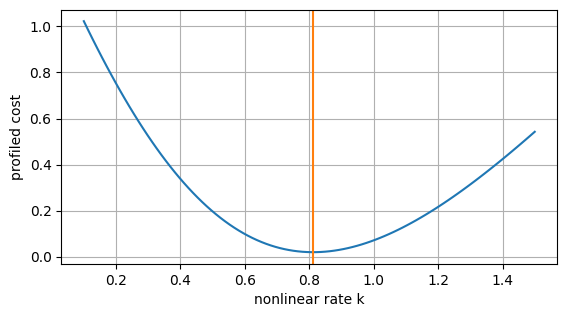

In [2]:
rng=np.random.default_rng(203)
t=np.linspace(0,4,40)
y=2.5*np.exp(-.8*t)+.4+rng.normal(0,.025,len(t))
def linear_part(k):
    return np.column_stack([np.exp(-k*t),np.ones_like(t)])
def projected_residual(theta):
    A=linear_part(theta[0])
    ac=np.linalg.lstsq(A,y,rcond=None)[0]
    return A@ac-y
outer=least_squares(projected_residual,[.5],bounds=([.01],[3.]))
ac=np.linalg.lstsq(linear_part(outer.x[0]),y,rcond=None)[0]
print('variable projection [a,k,c]:',np.r_[ac[0],outer.x[0],ac[1]])
assert outer.success
grid=np.linspace(.1,1.5,100)
plt.plot(grid,[.5*np.sum(projected_residual([k])**2) for k in grid])
plt.axvline(outer.x[0],color='C1')
plt.xlabel('nonlinear rate k');plt.ylabel('profiled cost');plt.show()

## 内层答案也会跟着变

上例让 SciPy 对“每次都重新求过内层的残差函数”做数值微分，因此包含了内层系数随 $k$ 改变的作用。手写外层雅可比时，不能把刚求出的 $a,c$ 当作永远不动；要用相应导数或专门的变量投影公式。

## 用走过的一步更新地图：割线条件

假如刚才走了 $s=x_{k+1}-x_k$，残差实际改变了 $y_r=r(x_{k+1})-r(x_k)$。旧影响表 $B$ 对这步的预测可能不准，我们让新表至少符合刚测到的关系：

$$B_{\rm new}s=y_r.$$

这叫**割线条件**：利用两个位置的差，校正变化规律。一个常见的秩一更新是

$$B_{\rm new}=B+\frac{(y_r-Bs)s^T}{s^Ts}.$$

“秩一”描述这次修正矩阵的结构，不是说整张表只剩一个独立方向。在把所有格子改变量的平方相加的意义下，也就是 Frobenius 范数，它是满足这一个条件的最小改动。

下面检查新表能否复现这一步实际变化。**符合一个方向的一次观测，不代表所有方向都准确**；噪声、很小的步或过期信息都可能使更新失效，需要重算和保护规则。

In [3]:
B=np.array([[1.,.2],[.1,2.],[.4,.3]])
s=np.array([.3,-.2]);delta_r=np.array([.5,-.1,.2])
updated=B+np.outer(delta_r-B@s,s)/(s@s)
print('secant error:',np.linalg.norm(updated@s-delta_r))
assert np.allclose(updated@s,delta_r)

secant error: 5.551115123125783e-17


## 为什么还会有混合与拟牛顿方法

GN 没有使用完整曲率。残差较大、被省略的 $\sum_i r_i\nabla^2r_i$ 重要时，可以尝试从历史变化估计缺失部分，这类思路叫**拟牛顿**：不用每次精确计算全部二阶导数，借助更新逐步近似。

与阻尼、信赖域结合的混合方法还需要规定何时切换、何时重置、失败后怎样恢复。不是给 $J^TJ$ 随便加张表就完成了一个可靠算法。

本附录只有可分问题和割线条件两个可运行实验。原参考书的完整混合 LM、割线 LM、割线狗腿，以及大规模稀疏求解器，没有在本版实现。继续读原书3.4—3.6节时，先问它在近似哪张表、用什么观测更新、失败时如何恢复，再去记名称。

## 检查题

问题一：刚才根本没移动，即 $s=0$，还能代入割线更新吗？

解答：不能，分母为零。非常小的步也会把噪声放大，应跳过或重建影响表。

问题二：外层参数少了，变量投影就一定更快更好吗？

解答：不一定。每次还要求内层，内层可能有约束、秩变化或昂贵计算。应按同一目标和精度比较实际结果与成本，不能只按参数个数排优劣。